In [14]:
from google.adk.agents import Agent
from google.adk.models.google_llm import Gemini
from google.adk.runners import InMemoryRunner
from google.adk.tools import google_search
from google.genai import types

print("✅ ADK components imported successfully.")

✅ ADK components imported successfully.


In [15]:
import os
from dotenv import load_dotenv

# Load environment variables from the .env file
load_dotenv()

# Retrieve the API key
google_api_key = os.getenv("GOOGLE_API_KEY")

# Verify it was loaded successfully (masks key for security)
if google_api_key:
    print(f"Loaded successfully: {google_api_key[:6]}...{google_api_key[-4:]}")
else:
    print("GOOGLE_API_KEY not found in .env")


Loaded successfully: AIzaSy...TC0w


####  Configure Retry Options
When working with LLMs, you may encounter transient errors like rate limits or temporary service unavailability. Retry options automatically handle these failures by retrying the request with exponential backoff.

In [16]:
retry_config=types.HttpRetryOptions(
    attempts=5,  # Maximum retry attempts
    exp_base=7,  # Delay multiplier
    initial_delay=1, # Initial delay before first retry (in seconds)
    http_status_codes=[429, 500, 503, 504] # Retry on these HTTP errors
)

### What is an AI Agent?
You've probably used an LLM like Gemini before, where you give it a prompt and it gives you a text response.

Prompt -> LLM -> Text

An AI Agent takes this one step further. An agent can think, take actions, and observe the results of those actions to give you a better answer.

Prompt -> Agent -> Thought -> Action -> Observation -> Final Answer

In this notebook, we'll build an agent that can take the action of searching Google. Let's see the difference!

### Define your agent
Now, let's build our agent. We'll configure an Agent by setting its key properties, which tell it what to do and how to operate.

To learn more, check out the documentation related to agents in ADK.

These are the main properties we'll set:

- name and description: A simple name and description to identify our agent.
- model: The specific LLM that will power the agent's reasoning. We'll use "gemini-3.5-flash-lite".
- instruction: The agent's guiding prompt. This tells the agent what its goal is and how to behave.
- tools: A list of tools that the agent can use. To start, we'll give it the google_search tool, which lets it find up-to-date information online.

### Run your agent
To run an agent, you need a Runner, which is the central component within ADK that acts as the orchestrator. It manages the conversation, sends our messages to the agent, and handles its responses.

Note that we are using the Python Runner directly in this notebook. You can also run agents using ADK command-line tools such as adk run, adk web, or adk api_server. To learn more, check out the documentation related to runtime in ADK.

Now you can call the .run_debug() method to send our prompt and get an answer.
This method abstracts the process of session creation and maintenance and is used in prototyping. 

In [17]:
root_agent = Agent(
    name="helpful_assistant",
    model=Gemini(
        model="gemini-3.5-flash-lite",
        retry_options=retry_config
    ),
    description="A simple agent that can answer general questions.",
    instruction="You are a helpful assistant. Use Google Search for current info or if unsure.",
    tools=[google_search],
)

print("✅ Root Agent defined.")

runner = InMemoryRunner(agent=root_agent)
print("✅ Runner created.")


✅ Root Agent defined.
✅ Runner created.


In [18]:
response = await runner.run_debug(
    "What is Agent Development Kit from Google? What languages is the SDK available in?"
)

helpful_assistant > The **Agent Development Kit (ADK)** from Google is an open-source, code-first development framework designed to help developers build, debug, evaluate, and deploy reliable AI agents and multi-agent systems at enterprise scale. 

Rather than relying purely on basic prompt scripts, ADK applies standard software development principles to AI. It features modular components, workflow runtimes (graph-based execution engines for deterministic pipelines), conversational memory, session management, built-in tools (like Google Search and custom API integrations), and support for multi-agent architectures where specialized agents collaborate or delegate tasks. It also natively incorporates open standards like the **Model Context Protocol (MCP)** and the **Agent2Agent (A2A) protocol** for cross-language and cross-service interoperability.

### Supported Languages
The ADK SDK is available in **5 programming languages**, allowing development teams to build agents in their preferr

### How does it work?¶
The agent performed a Google Search to get the latest information about ADK, and it knew to use this tool because:

- The agent inspects and is aware of which tools it has available to use.
- The agent's instructions specify the use of the search tool to get current information or if it is unsure of an answer.

#### Ask it a question that requires current information.

Try one of these, or make up your own:

- What's the weather in London?
- Who won the last soccer world cup?
- What new movies are showing in theaters now?

In [19]:
response = await runner.run_debug('How is the weather in Bengaluru?')

helpful_assistant > In Bengaluru, the weather is generally cloudy with temperatures hovering around 27°C to 28°C (with highs expected to reach around 31°+ and lows dipping to around 21°C). There is a possibility of light rain or drizzle in some areas.


In [20]:
print(response)

[Event(model_version='gemini-3.5-flash-lite', content=Content(
  parts=[
    Part(
      text='In Bengaluru, the weather is generally cloudy with temperatures hovering around 27°C to 28°C (with highs expected to reach around 31°+ and lows dipping to around 21°C). There is a possibility of light rain or drizzle in some areas.',
      thought_signature=b'\x12`\n^\x01i\x14}\x13\xdf\xc6\x97\xe7T\x0b\xadgO\xb3D]\xa0\xc5[\xfb\x01\x083\xb2! \x8f\xcf\xc4\xc4\x8c\xf6\n\xe8\\Nv\xca\xf0\xf9\x1a\x17^k\xef\xf7\xe0tp\xe7\xca\xbdI\xab\xf4x\xebM\x96\x1e\x04\x18\xfe\xab\x15\xfd\x9a\x91\x14\xfctd\x16\x9b?\xf50\xec\xea\xd9\xfe\x92\x04La\x8c\\\xf7\xb3d3\xb8\x1b'
    ),
  ],
  role='model'
), grounding_metadata=GroundingMetadata(
  grounding_chunks=[
    GroundingChunk(
      web=GroundingChunkWeb(
        title='imd.gov.in',
        uri='https://vertexaisearch.cloud.google.com/grounding-api-redirect/AUZIYQF4YavkCt1n5yWdlfHqYYp-BApeLgvQg8IjJC4BKy3B6RKr6-nkWdAZXtsT7-Z-kaPbk8_5LTSnHebriIbOEgJuV0zmjzy-jcoA5sh

### Try the ADK Web Interface
ADK includes a built-in web interface for interactively chatting with, testing, and debugging your agents.

To use the ADK web UI, you'll need to create an agent with Python files using the adk create command.

Run the command below to generate a sample_agent folder that contains all the necessary files, including agent.py for your code, an .env file with your API key pre-configured, and an __init__.py file.

Post that in the terminal start adk web to get the URL of ADK and play with the agent

In [21]:
# !adk create sample_agent --model gemini-3.5-flash-lite --api_key $GOOGLE_API_KEY

### Create a brand new agent app on ADK Web
To have a new agent appear in the dropdown menu on the ADK Web interface next to sample_agent:

Create a new folder (e.g., custom_agent/) in your project root.
Add these two files inside it:
hese two files inside it:

custom_agent/__init__.py
``` python
from . import agent
```

custom_agent/agent.py
``` python
from google.adk.agents.llm_agent import Agent
root_agent = Agent(
    name="root_agent",
    model="gemini-3.5-flash-lite",  # or 'gemini-2.5-flash'
    description="A specialized assistant for user tasks.",
    instruction="You are a helpful expert assistant. Answer user queries clearly.",
)
```
Once saved, adk web will automatically detect the new folder and display custom_agent in the agent selection dropdown in your browser. (Remember to use underscores _ and not hyphens -).

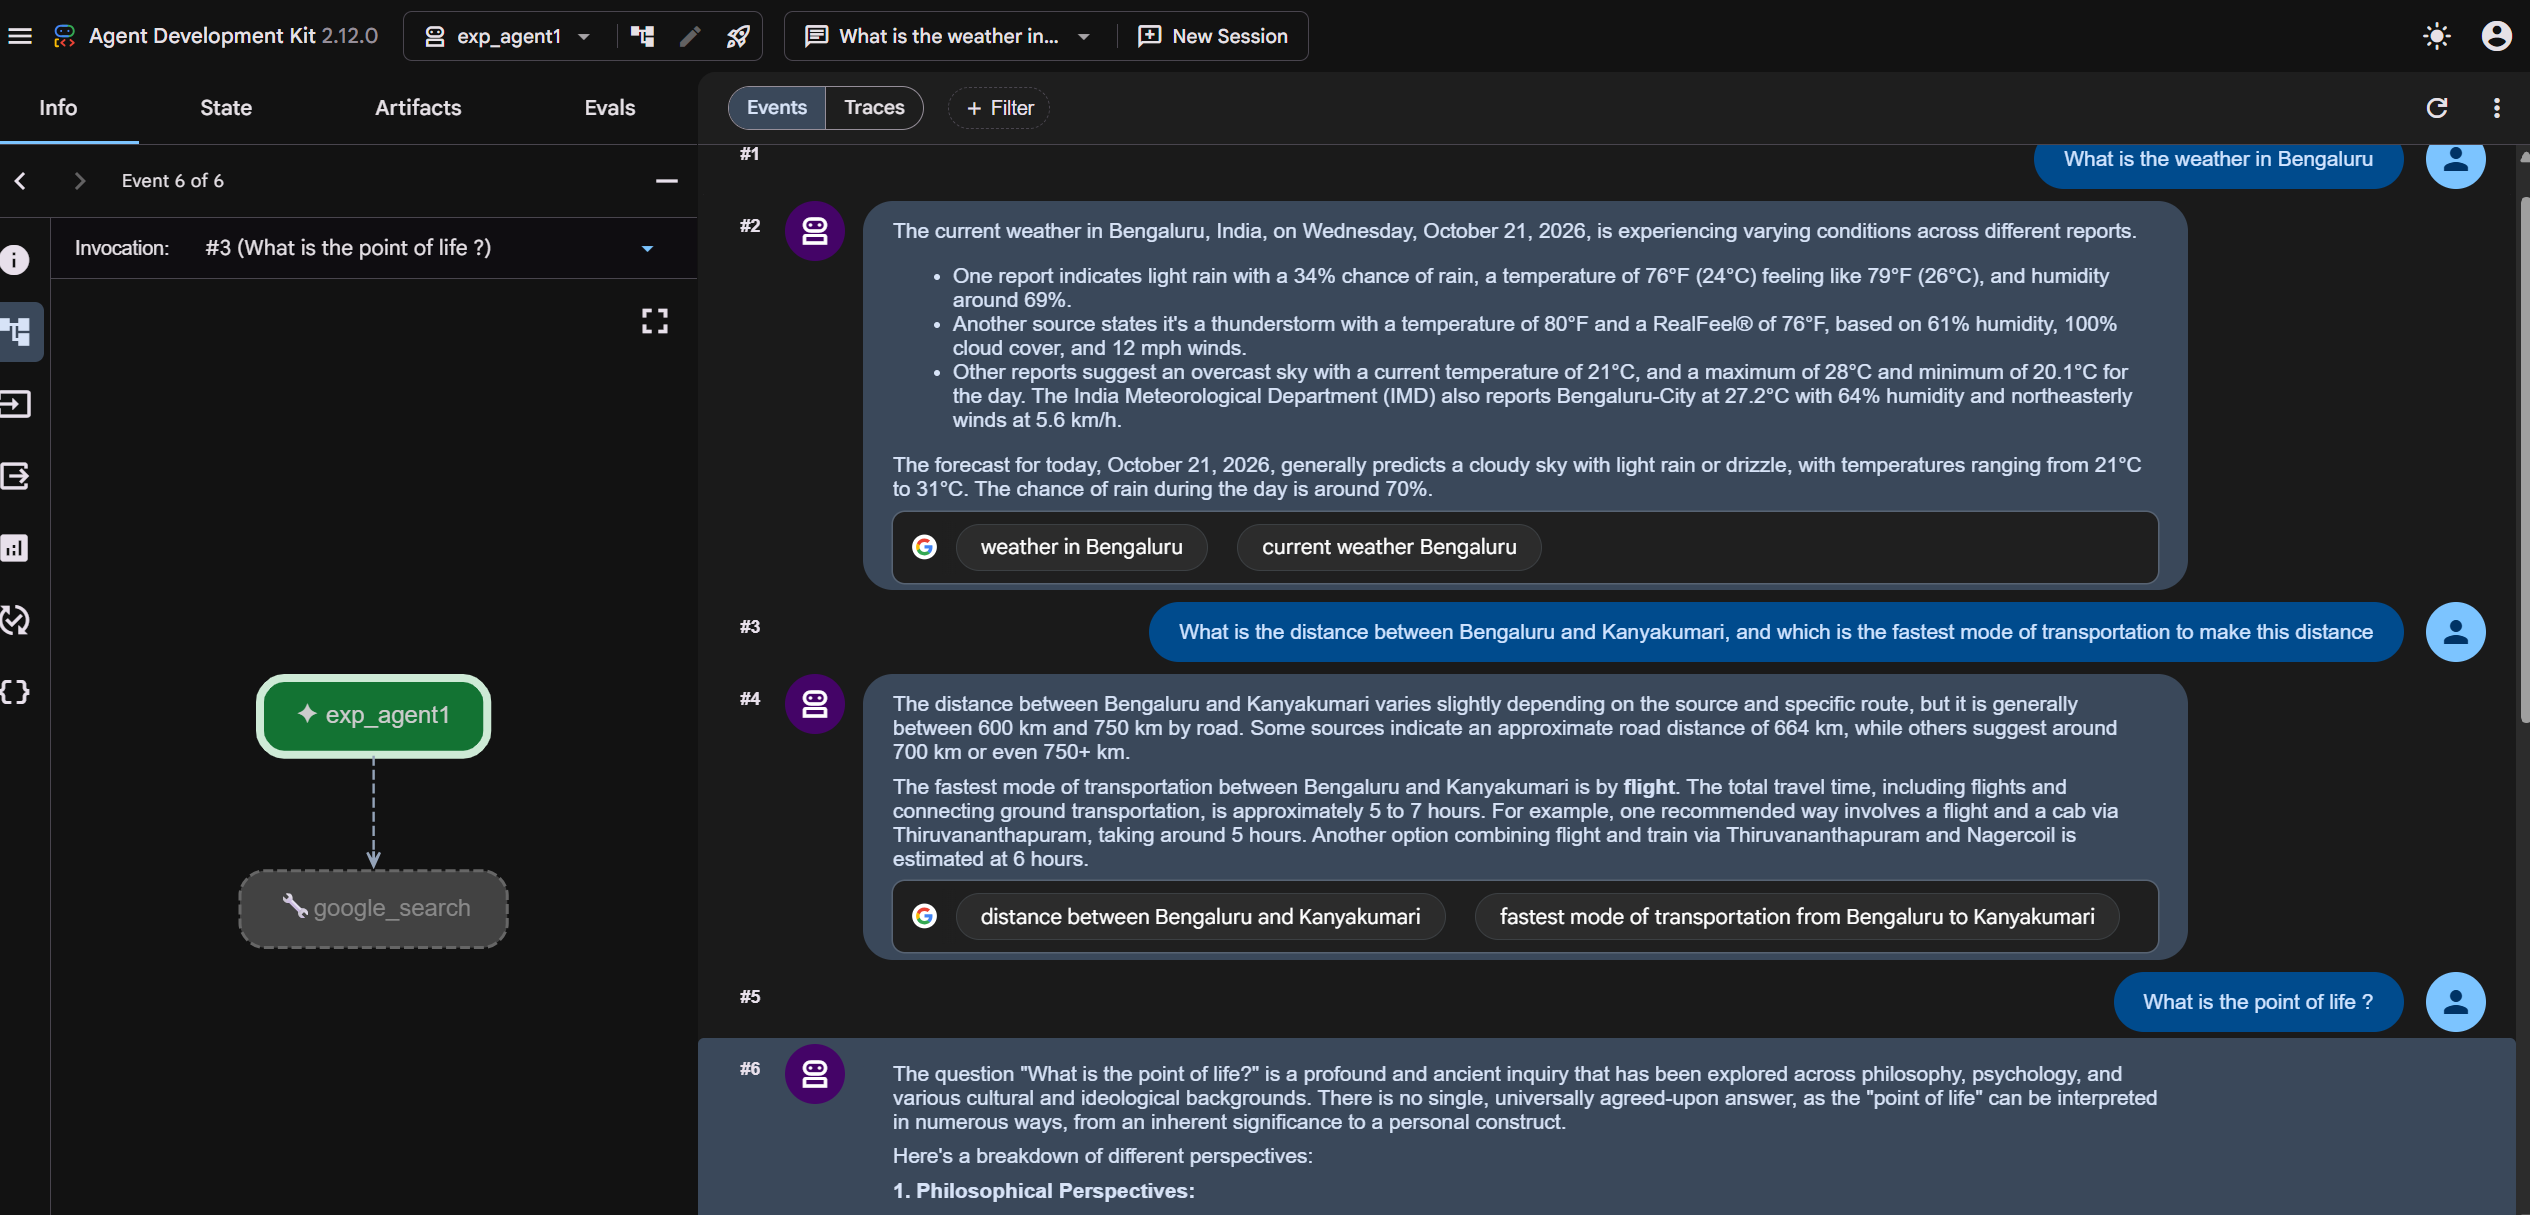

You've built and run your first agent with ADK! You've just seen the core concept of agent development in action.

The big takeaway is that your agent didn't just respond—it reasoned that it needed more information and then acted by using a tool. This ability to take action is the foundation of all agent-based AI.

Refer to the below Documentation:
* [ADK Documentation](https://google.github.io/adk-docs/)
* [ADK Quickstart for Python](https://google.github.io/adk-docs/get-started/python/)
* [ADK Agents Overview](https://google.github.io/adk-docs/agents/)
* [ADK Tools Overview](https://google.github.io/adk-docs/tools/)

